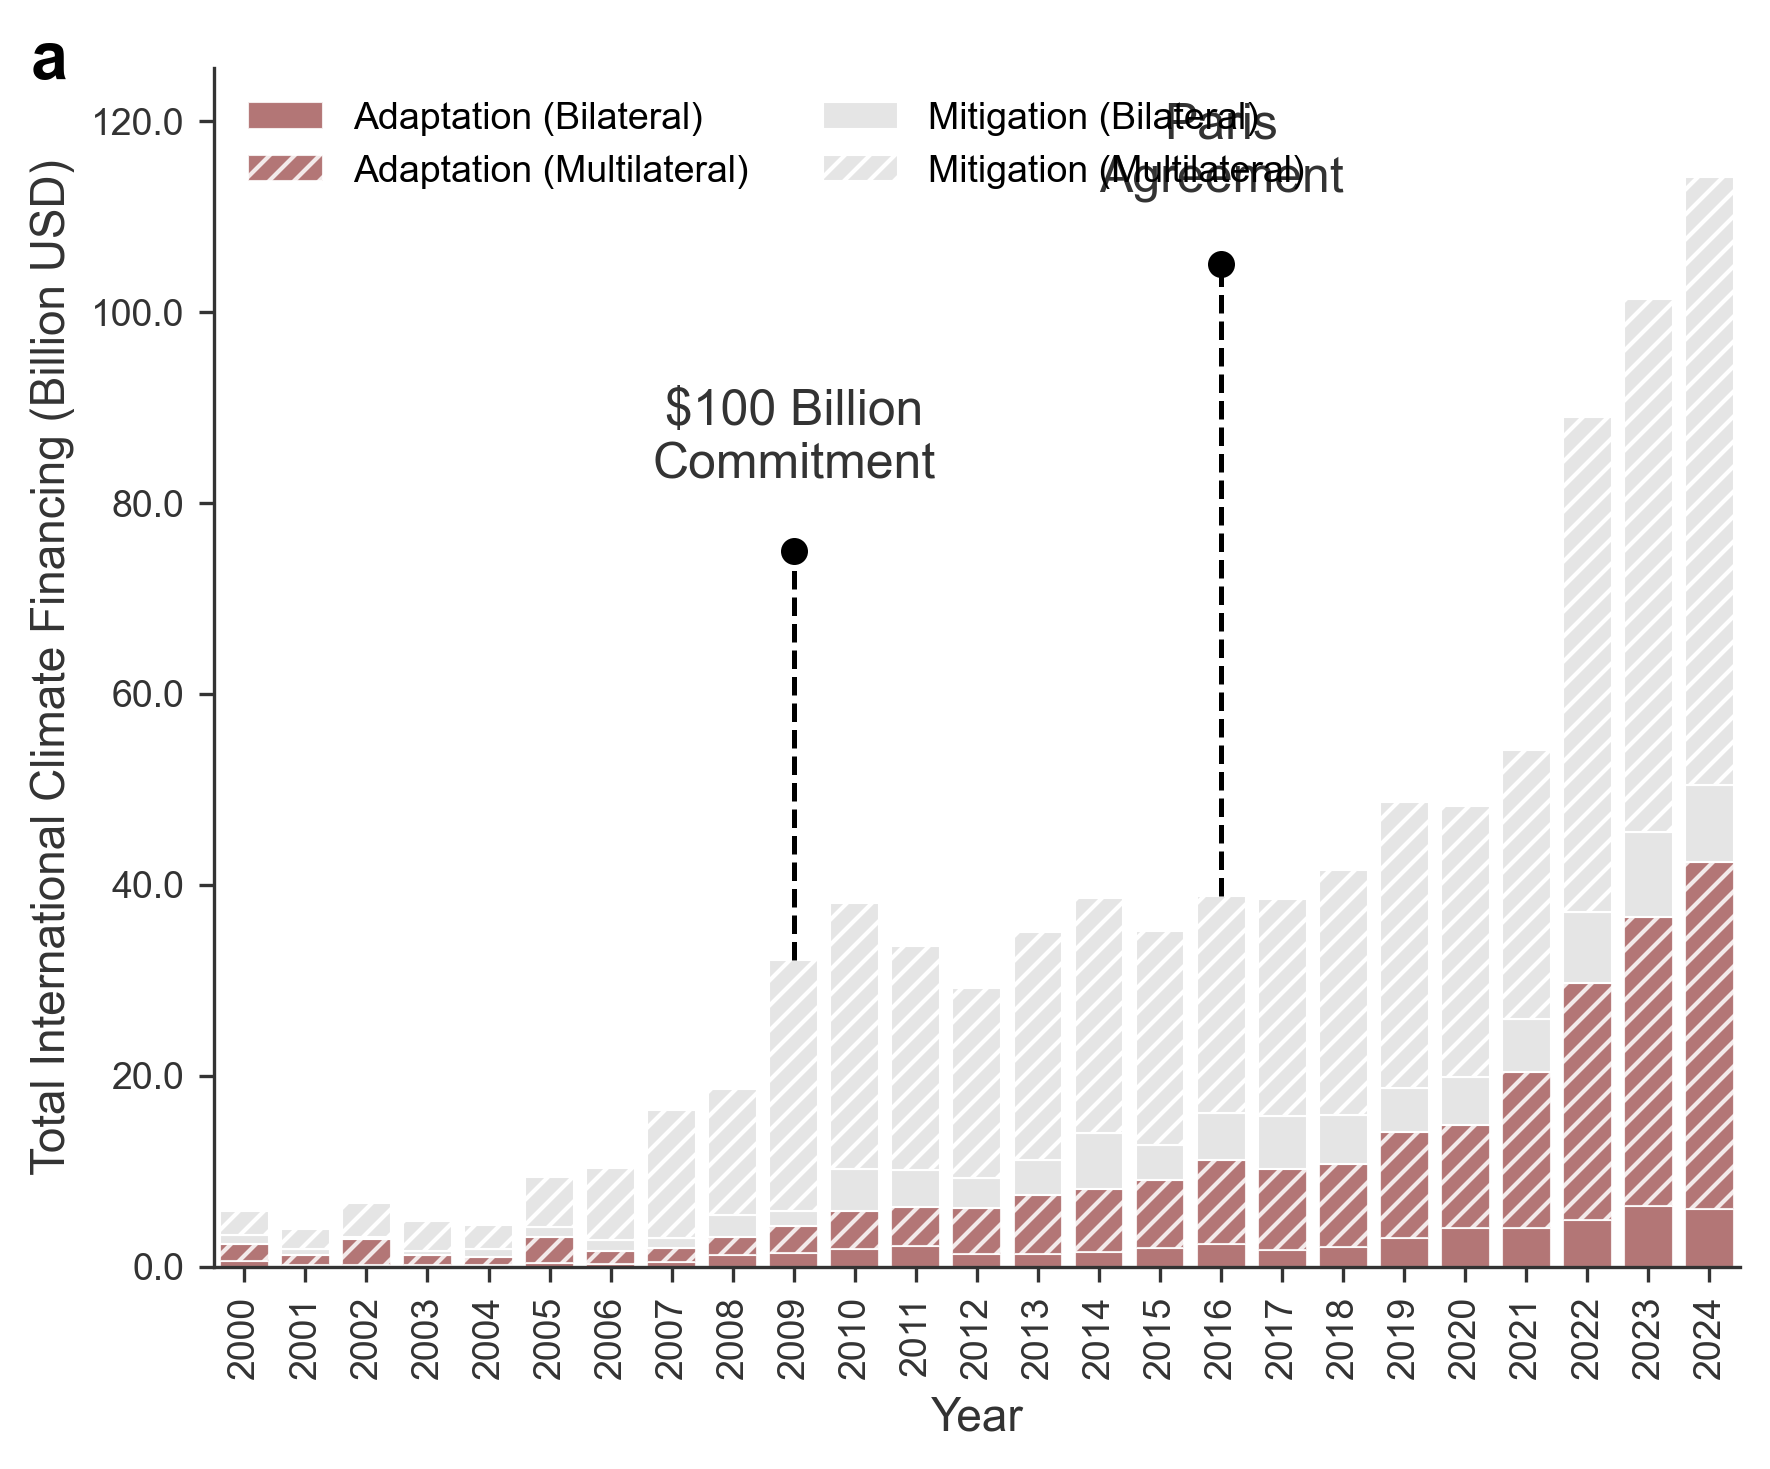

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# 1. Data processing
file_path = '../output/data/Climate_Finance_2000_2024.xlsx'
df = pd.read_excel(file_path)
# Source data are in USD million; Fig. 1 is shown in USD billion
fin_cols = ['Bilateral_Adaptation', 'Multilateral_Adaptation', 'Bilateral_Mitigation', 'Multilateral_Mitigation']
df[fin_cols] = df[fin_cols] / 1000

# Keep 2000-2024
df_filtered = df[(df['Year'] >= 2000) & (df['Year'] <= 2024)]

# Group by year and keep the 4 finance columns
df_yearly = df_filtered.groupby('Year')[['Bilateral_Adaptation', 
                                         'Multilateral_Adaptation',
                                         'Bilateral_Mitigation', 
                                         'Multilateral_Mitigation']].sum().reset_index()

# 2. Global style - Nature journal settings
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica Neue', 'DejaVu Sans'], 
    'font.size': 10,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.linewidth': 0.8
})

# --- Emphasise adaptation, de-emphasise the background ---
adaptation_color = '#A65E5E'  # deep wine red (visual focus)

# Use explicit light greys instead of alpha transparency
mitigation_bg_color = '#E5E5E5'     # light grey fill for mitigation
mitigation_hatch_color = '#B0B0B0'  # hatch colour for multilateral mitigation (slightly darker grey)

marker_color = 'black'       # marker colour
text_color = '#333333'       # text colour

# 3. Plot
fig, ax = plt.subplots(figsize=(6, 5), dpi=300)

# Extract data
x = df_yearly['Year']
y1 = df_yearly['Bilateral_Adaptation']
y2 = df_yearly['Multilateral_Adaptation']
y3 = df_yearly['Bilateral_Mitigation']
y4 = df_yearly['Multilateral_Mitigation']

# Stack baselines
total_adaptation = y1 + y2
total_heights = y1 + y2 + y3 + y4 

# --- Stacked bars ---
# Adaptation: dark colour, high opacity (0.95), white edges
ax.bar(x, y1, color=adaptation_color, edgecolor='white', linewidth=0.5, label='Adaptation (Bilateral)', alpha=0.85)
ax.bar(x, y2, bottom=y1, color=adaptation_color, edgecolor='white', hatch='////', linewidth=0.5, label='Adaptation (Multilateral)', alpha=0.85)

# Mitigation: muted but still distinguishable:
# 1. Bilateral: solid light grey, white edges
ax.bar(x, y3, bottom=total_adaptation, color=mitigation_bg_color, edgecolor='white', linewidth=0.5, label='Mitigation (Bilateral)')
# 2. Multilateral: light grey fill, edgecolor (hatch colour) set to a darker grey (mitigation_hatch_color)
ax.bar(x, y4, bottom=total_adaptation+y3, color=mitigation_bg_color, edgecolor='white', hatch='////', linewidth=0.5, label='Mitigation (Multilateral)')

# 4. Formatting
plt.xticks(x, rotation=90)
ax.set_xlabel('Year', color=text_color)

# Auto-adjust the y-axis upper limit
ax.set_xlim(1999.5, 2024.5)
ax.set_ylim(0, total_heights.max() * 1.1)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
ax.set_ylabel('Total International Climate Financing (Billion USD)', color=text_color)

ax.grid(False)
ax.tick_params(axis='both', colors=text_color)
for spine in ax.spines.values():
    spine.set_color(text_color)

ax.text(-0.12, 0.98, 'a', transform=ax.transAxes, 
        fontsize=16, fontweight='bold', va='bottom', ha='left')

# Legend: two columns, upper left
ax.legend(loc='upper left', frameon=False, ncol=2)

# 5. Annotate key milestones 
x1 = 2009
y1_dot = 75.0 if 75.0 < ax.get_ylim()[1] else ax.get_ylim()[1] * 0.9 
if x1 in x.values:
    y1_top = total_heights[x == x1].values[0]
    plt.scatter(x1, y1_dot, s=30, color=marker_color, zorder=5)
    plt.vlines(x1, y1_top, y1_dot, colors=marker_color, linestyles='--', linewidth=1.2)
    plt.annotate('$100 Billion\nCommitment', xy=(x1, y1_dot), xytext=(0, 15), 
                 textcoords='offset points', ha='center', va='bottom', 
                 fontsize=12, linespacing=1.2, color=text_color)

x2 = 2016
y2_dot = 105.0 if 105.0 < ax.get_ylim()[1] else ax.get_ylim()[1] * 0.95 
if x2 in x.values:
    y2_top = total_heights[x == x2].values[0]
    plt.scatter(x2, y2_dot, s=30, color=marker_color, zorder=5)
    plt.vlines(x2, y2_top, y2_dot, colors=marker_color, linestyles='--', linewidth=1.2)
    plt.annotate('Paris\nAgreement', xy=(x2, y2_dot), xytext=(0, 15), 
                 textcoords='offset points', ha='center', va='bottom', 
                 fontsize=12, linespacing=1.2, color=text_color)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Tight layout to avoid overlaps
plt.tight_layout()

# 6. Show
plt.savefig('../output/figures/Fig.1_Climate_Finance_Chart_Nature_GreyMitigation.png', bbox_inches='tight', dpi=900)
plt.show()